## 1. Import Library dan Konfigurasi Path 

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150

DATA_DIR = Path("dataset/sst_5_wilayah") if Path("dataset/sst_5_wilayah").exists() else Path("../dataset/sst_5_wilayah")
OUTPUT_DIR = Path("reports/figures") if Path("reports").exists() else Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WILAYAH = [
    "Pasifik_Nino34",
    "Selat_Makassar",
    "Selat_Karimata",
    "Selatan_Jawa",
    "Maluku_Utara_Papua"
]

## 2. Memuat Data dan Menghitung Rata-rata Spasial Harian

In [10]:
daily_sst = {}

for region in WILAYAH:
    files = sorted([f for f in DATA_DIR.glob(f"{region}_*.nc") if "2015_2025" not in f.name])
    if not files:
        continue
    ds_list = []
    for f in files:
        with xr.open_dataset(f) as ds:
            da = ds['sst'].load()
            if 'zlev' in da.dims:
                da = da.squeeze('zlev', drop=True)
            ds_list.append(da)
            
    combined = xr.concat(ds_list, dim='time').sortby('time')
    _, idx = np.unique(combined['time'], return_index=True)
    combined = combined.isel(time=idx)
    daily_sst[region] = combined.mean(dim=['latitude', 'longitude'], skipna=True).to_pandas()

df_daily = pd.DataFrame(daily_sst)
df_daily.index = pd.to_datetime(df_daily.index)
print(df_daily.head())

                     Pasifik_Nino34  Selat_Makassar  Selat_Karimata  \
time                                                                  
2015-01-01 12:00:00       26.627192       29.316582       28.672382   
2015-01-02 12:00:00       26.662533       29.317404       28.459431   
2015-01-03 12:00:00       26.689571       29.286520       28.364906   
2015-01-04 12:00:00       26.724104       29.281708       28.463875   
2015-01-05 12:00:00       26.746599       29.274618       28.445908   

                     Selatan_Jawa  Maluku_Utara_Papua  
time                                                   
2015-01-01 12:00:00     28.889095           29.575830  
2015-01-02 12:00:00     28.777308           29.567276  
2015-01-03 12:00:00     28.829336           29.535147  
2015-01-04 12:00:00     28.873768           29.507259  
2015-01-05 12:00:00     28.860243           29.447506  


## 3. Perhitungan Anomali Suhu (SSTA) & Pelabelan Status ENSO

In [11]:
climatology = df_daily.groupby(df_daily.index.dayofyear).transform('mean')
df_ssta = df_daily - climatology

df_ssta['ONI_Nino34'] = df_ssta['Pasifik_Nino34'].rolling(window=90, min_periods=30, center=True).mean()

def label_enso(val):
    if pd.isna(val):
        return np.nan
    elif val >= 0.5:
        return 'El Nino'
    elif val <= -0.5:
        return 'La Nina'
    else:
        return 'Netral'

df_ssta['ENSO_Status'] = df_ssta['ONI_Nino34'].apply(label_enso)
print(df_ssta[['Pasifik_Nino34', 'ONI_Nino34', 'ENSO_Status']].dropna().head(10))

                     Pasifik_Nino34  ONI_Nino34 ENSO_Status
time                                                       
2015-01-01 12:00:00        0.033051    0.414226      Netral
2015-01-02 12:00:00        0.078394    0.414573      Netral
2015-01-03 12:00:00        0.103382    0.414767      Netral
2015-01-04 12:00:00        0.126904    0.413939      Netral
2015-01-05 12:00:00        0.157602    0.411892      Netral
2015-01-06 12:00:00        0.163973    0.408458      Netral
2015-01-07 12:00:00        0.168961    0.405295      Netral
2015-01-08 12:00:00        0.164200    0.402728      Netral
2015-01-09 12:00:00        0.118950    0.401507      Netral
2015-01-10 12:00:00        0.082819    0.402941      Netral


## 4. Visualisasi Timeline Fase ENSO (Ambang Batas ±0.5°C)


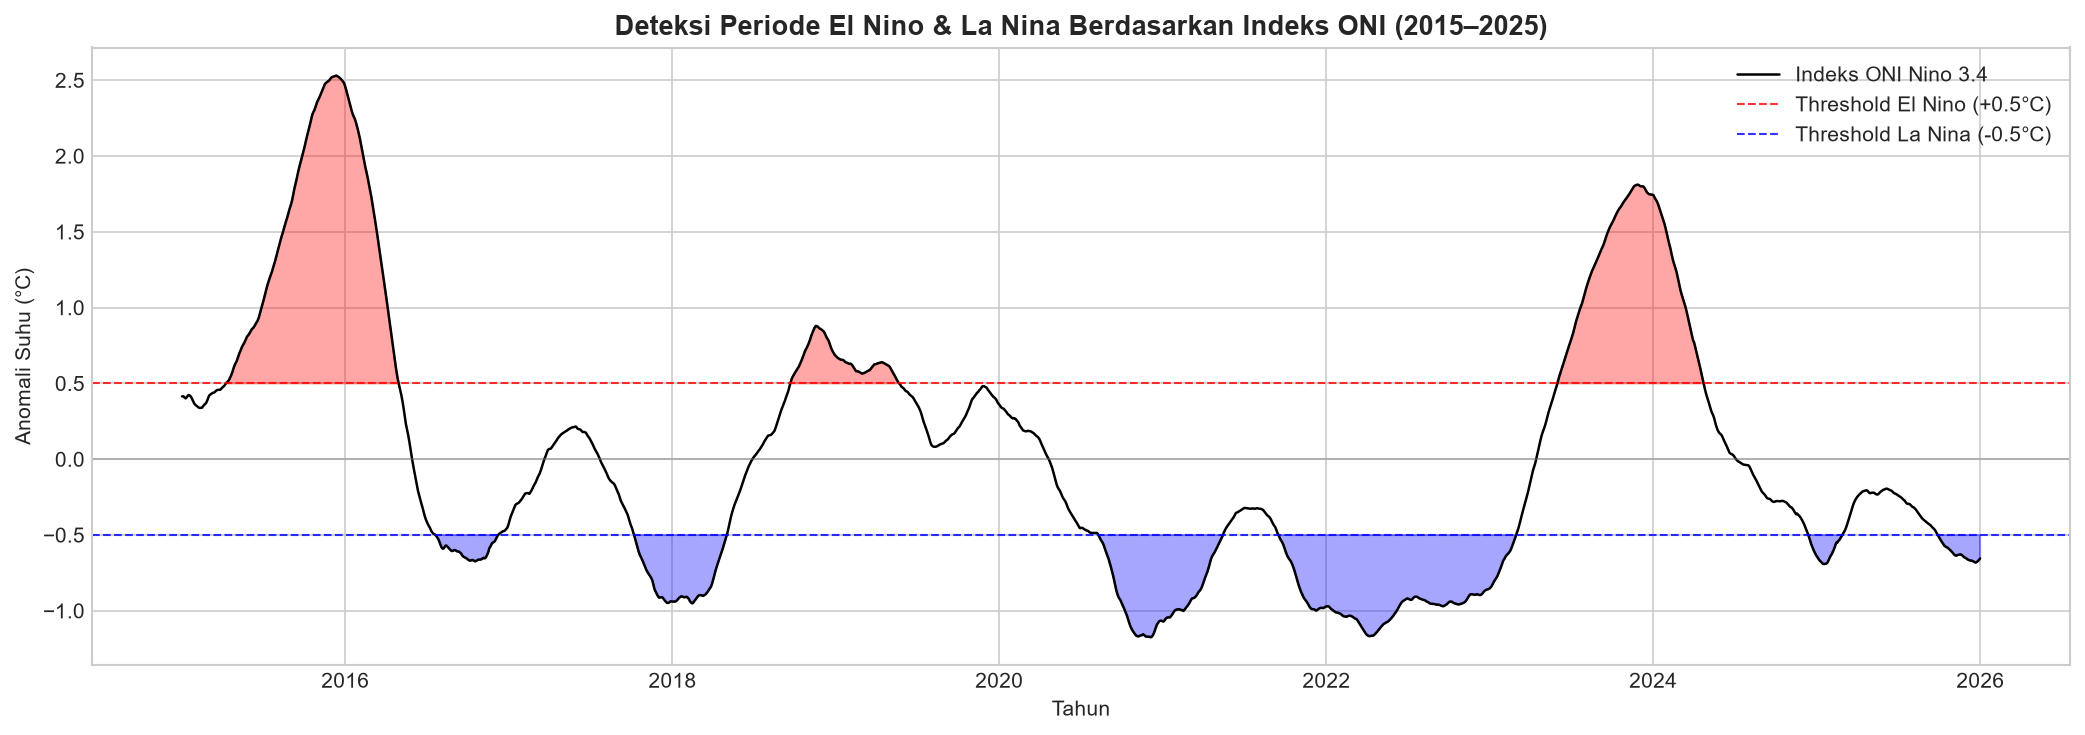

In [12]:
oni = df_ssta['ONI_Nino34'].dropna()

plt.figure(figsize=(14, 5))
plt.plot(oni.index, oni.values, color='black', linewidth=1.2, label='Indeks ONI Nino 3.4')

plt.axhline(0.5, color='red', linestyle='--', linewidth=1, alpha=0.8, label='Threshold El Nino (+0.5°C)')
plt.axhline(-0.5, color='blue', linestyle='--', linewidth=1, alpha=0.8, label='Threshold La Nina (-0.5°C)')
plt.axhline(0.0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)

plt.fill_between(oni.index, oni.values, 0.5, where=(oni.values >= 0.5), color='red', alpha=0.35, interpolate=True)
plt.fill_between(oni.index, oni.values, -0.5, where=(oni.values <= -0.5), color='blue', alpha=0.35, interpolate=True)

plt.title("Deteksi Periode El Nino & La Nina Berdasarkan Indeks ONI (2015–2025)", fontsize=13, fontweight='bold')
plt.ylabel("Anomali Suhu (°C)")
plt.xlabel("Tahun")
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_timeline_enso_detection.png")
plt.show()

## 5. Analisis Distribusi & Proporsi Kelas Target (Class Imbalance)

             Jumlah Hari  Persentase (%)
ENSO_Status                             
Netral              1735           43.36
La Nina             1322           33.04
El Nino              944           23.59


C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_27240\3169730265.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=status_counts.index, y=status_counts.values, palette=palette, ax=axes[0])


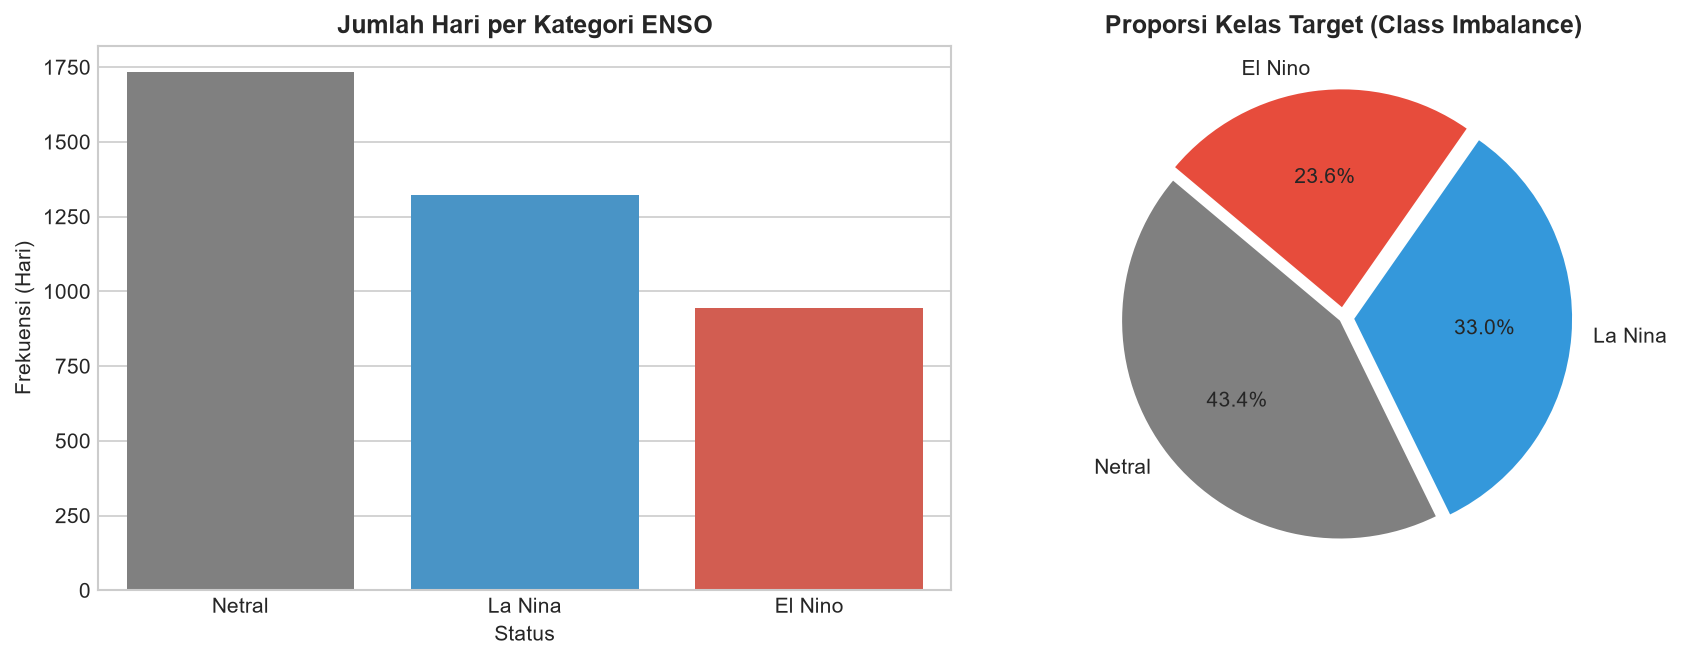

In [13]:
status_counts = df_ssta['ENSO_Status'].value_counts()
status_pct = df_ssta['ENSO_Status'].value_counts(normalize=True) * 100

df_dist = pd.DataFrame({'Jumlah Hari': status_counts, 'Persentase (%)': status_pct.round(2)})
print(df_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

palette = {'Netral': 'gray', 'El Nino': '#e74c3c', 'La Nina': '#3498db'}
sns.barplot(x=status_counts.index, y=status_counts.values, palette=palette, ax=axes[0])
axes[0].set_title("Jumlah Hari per Kategori ENSO", fontweight='bold')
axes[0].set_ylabel("Frekuensi (Hari)")
axes[0].set_xlabel("Status")

axes[1].pie(
    status_counts.values, 
    labels=status_counts.index, 
    autopct='%1.1f%%', 
    colors=[palette[k] for k in status_counts.index], 
    startangle=140,
    explode=(0.02, 0.05, 0.05)
)
axes[1].set_title("Proporsi Kelas Target (Class Imbalance)", fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_enso_class_distribution.png")
plt.show()

## 6. Analisis Gradien Suhu Zonal (Warm Pool vs Pasifik Tengah)

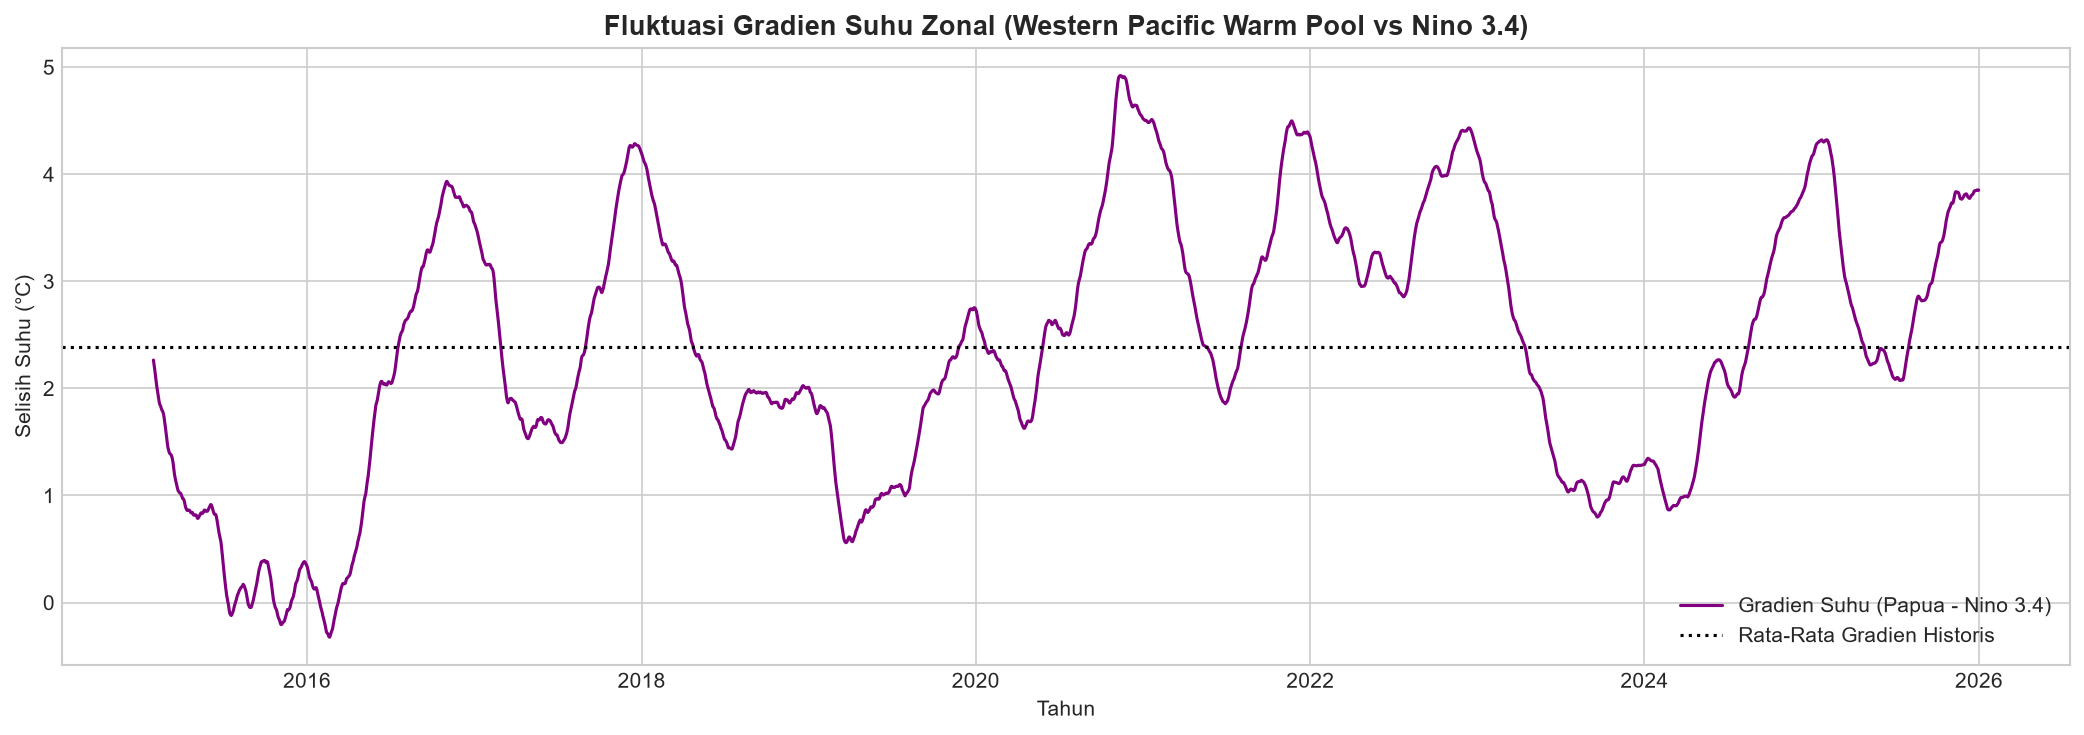

In [14]:
df_ssta['Gradien_Zonal'] = df_daily['Maluku_Utara_Papua'] - df_daily['Pasifik_Nino34']

plt.figure(figsize=(14, 5))
plt.plot(df_ssta['Gradien_Zonal'].rolling(30).mean(), color='purple', linewidth=1.5, label='Gradien Suhu (Papua - Nino 3.4)')
plt.axhline(df_ssta['Gradien_Zonal'].mean(), color='black', linestyle=':', label='Rata-Rata Gradien Historis')

plt.title("Fluktuasi Gradien Suhu Zonal (Western Pacific Warm Pool vs Nino 3.4)", fontsize=13, fontweight='bold')
plt.ylabel("Selisih Suhu (°C)")
plt.xlabel("Tahun")
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_zonal_temperature_gradient.png")
plt.show()

## 7. Analisis Autokorelasi & Penentuan Fitur Lag (ACF & PACF)

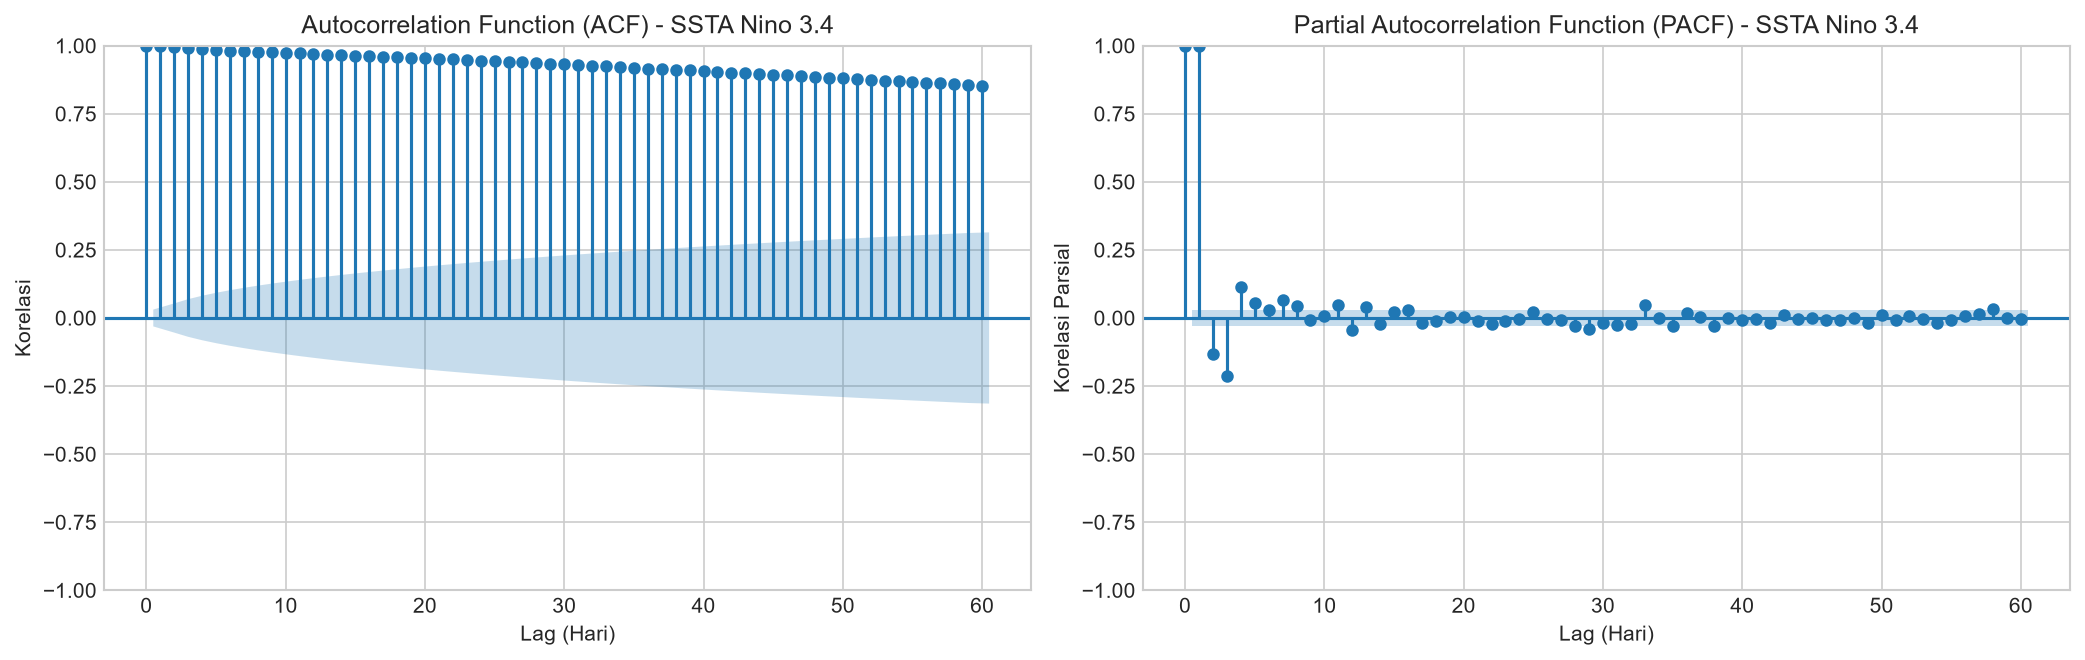

In [15]:
ssta_clean = df_ssta['Pasifik_Nino34'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_acf(ssta_clean, lags=60, ax=axes[0], title="Autocorrelation Function (ACF) - SSTA Nino 3.4")
axes[0].set_xlabel("Lag (Hari)")
axes[0].set_ylabel("Korelasi")

plot_pacf(ssta_clean, lags=60, ax=axes[1], title="Partial Autocorrelation Function (PACF) - SSTA Nino 3.4", method='ywm')
axes[1].set_xlabel("Lag (Hari)")
axes[1].set_ylabel("Korelasi Parsial")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_acf_pacf_lag_analysis.png")
plt.show()

## 8. Analisis Dampak Telekoneksi ke Perairan Indonesia (Scatter & Regresi)

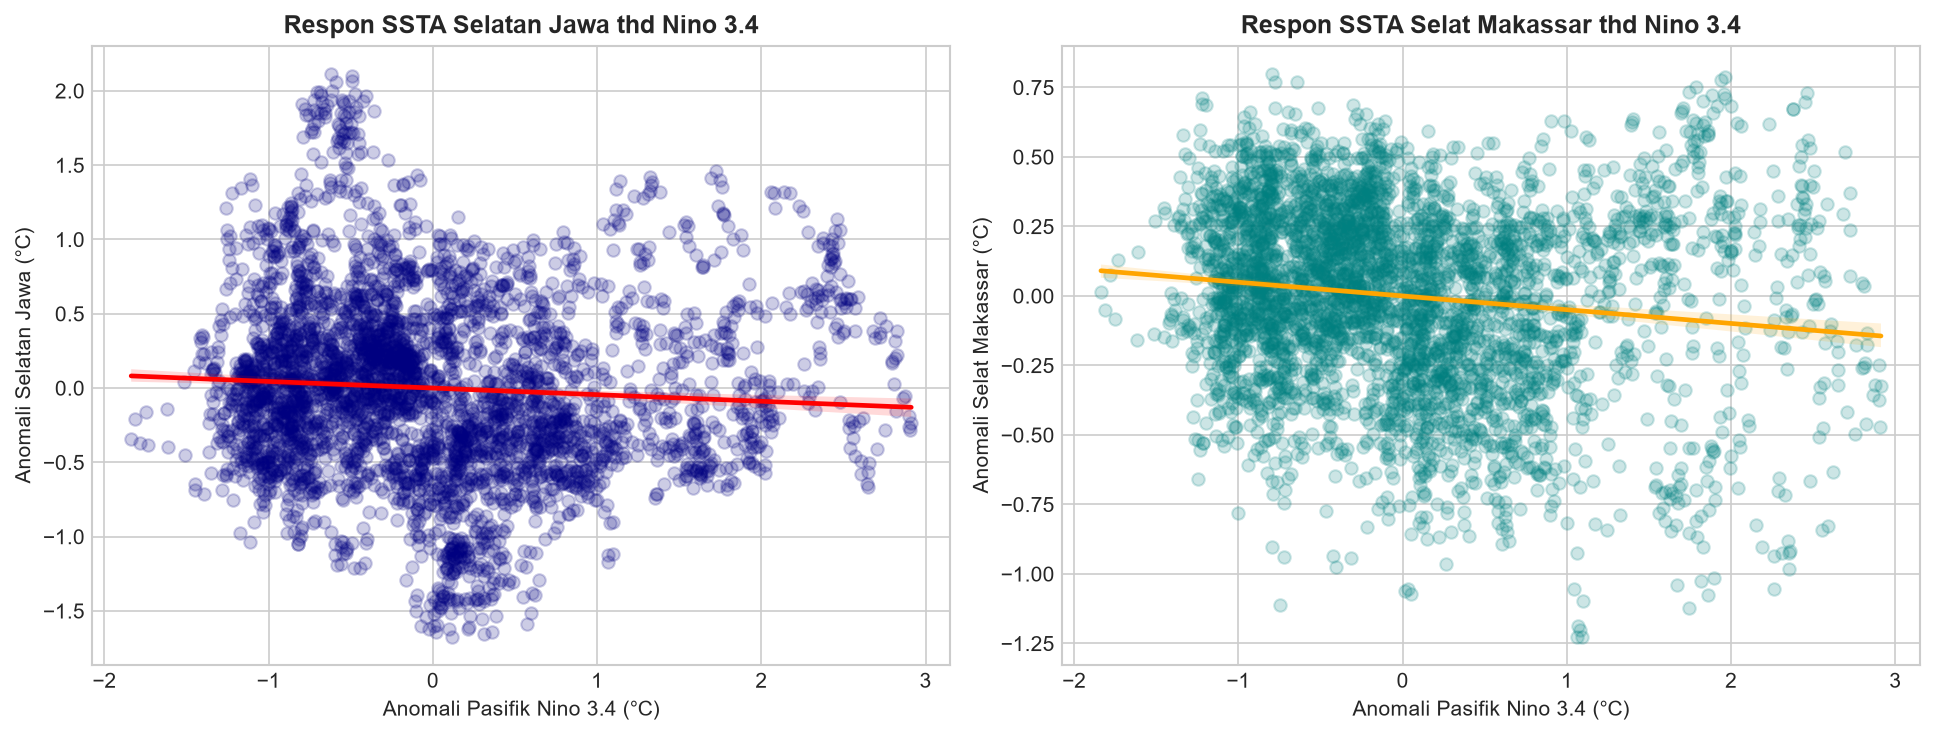

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    data=df_ssta, 
    x='Pasifik_Nino34', 
    y='Selatan_Jawa', 
    ax=axes[0], 
    scatter_kws={'alpha': 0.2, 'color': 'navy'}, 
    line_kws={'color': 'red'}
)
axes[0].set_title("Respon SSTA Selatan Jawa thd Nino 3.4", fontweight='bold')
axes[0].set_xlabel("Anomali Pasifik Nino 3.4 (°C)")
axes[0].set_ylabel("Anomali Selatan Jawa (°C)")

sns.regplot(
    data=df_ssta, 
    x='Pasifik_Nino34', 
    y='Selat_Makassar', 
    ax=axes[1], 
    scatter_kws={'alpha': 0.2, 'color': 'teal'}, 
    line_kws={'color': 'orange'}
)
axes[1].set_title("Respon SSTA Selat Makassar thd Nino 3.4", fontweight='bold')
axes[1].set_xlabel("Anomali Pasifik Nino 3.4 (°C)")
axes[1].set_ylabel("Anomali Selat Makassar (°C)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "10_teleconnection_scatter_regression.png")
plt.show()
